# Citi Bike: How New York Moves by Bike

Three months of Citi Bike trips: when people ride, how rain changes that, which stations empty out on weekday mornings, and a next-day forecast of each station's rides. DuckDB SQL (`queries.sql`) cleans and aggregates the 15.6 million raw trips; pandas, NumPy and scikit-learn work on the small results.

## Setup

The raw CSVs are cleaned once into `data/trips.parquet`, which removes 9,845 of 15,623,841 rows; every later query reads that file. Holidays count as weekend days throughout. The weather is saved to `data/` on the first run and read from disk after that, because Open-Meteo revises recent data and re-downloading it changed the results. With `USE_ATHENA = True`, the three analysis queries run on Amazon Athena against Parquet in S3 (see `aws/`); set it to `False` to run everything locally.

In [1]:
from pathlib import Path

import duckdb
import holidays
import httpx
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

plt.rcParams.update({"font.size": 12, "figure.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, RED = "#0073ff", "#ff7640", "#e24b4a"

USE_ATHENA = True  # True: the three analysis queries run on Athena (see aws/); False: everything runs locally in DuckDB


def query(name):
    """Return the SQL text of one named query from queries.sql."""
    sql = Path("queries.sql").read_text()
    return sql.split(f"-- name: {name}\n")[1].split("-- name:")[0]


def load(name, **values):
    """Run one named query on Athena or local DuckDB and return a DataFrame."""
    if USE_ATHENA:
        from aws import athena
        return athena.run(name, **values)
    return con.sql(query(name)).df()  # locally, DuckDB reads holidays from the registered table


def save_chart(fig, filename, source):
    """Add a source note at the bottom and save to docs/ at 1200 x 700 px."""
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    fig.text(0.01, 0.015, source, fontsize=9, color="gray")
    fig.savefig(Path("docs") / filename, dpi=100)

In [2]:
Path("docs").mkdir(exist_ok=True)
con = duckdb.connect()
if not Path("data/trips.parquet").exists():
    con.execute(query("clean_trips"))
con.sql(query("station_events"))

In [3]:
hourly = load("hourly_trips")
start, end = hourly["date"].min(), hourly["date"].max()
TRIPS_SOURCE = f"Source: Citi Bike trip data, {start:%b %-d} to {end:%b %-d, %Y}"

ny_holidays = holidays.country_holidays("US", subdiv="NY", years=range(start.year, end.year + 1))
holidays_df = pd.DataFrame({"date": pd.to_datetime(list(ny_holidays.keys())), "name": list(ny_holidays.values())})
holidays_df = holidays_df[holidays_df["date"].between(start, end)].sort_values("date")
con.register("holidays", holidays_df)  # lets the SQL skip holidays

hourly["is_weekday"] = (hourly["date"].dt.dayofweek < 5) & ~hourly["date"].isin(holidays_df["date"])
daily = hourly.groupby(["date", "is_weekday"], as_index=False)["trips"].sum()
holidays_df

,date,name
2,2026-06-19,Juneteenth National Independence Day
4,2026-07-03,Independence Day (observed)
3,2026-07-04,Independence Day


In [4]:
WEATHER_FILE = Path(f"data/weather_{start:%Y-%m-%d}_{end:%Y-%m-%d}.csv")

if not WEATHER_FILE.exists():
    params = {"latitude": 40.7812, "longitude": -73.9665, "daily": "temperature_2m_max,precipitation_sum",  # Central Park
              "temperature_unit": "fahrenheit", "precipitation_unit": "inch", "timezone": "America/New_York",
              "start_date": f"{start:%Y-%m-%d}", "end_date": f"{end:%Y-%m-%d}"}
    response = httpx.get("https://archive-api.open-meteo.com/v1/archive", params=params, timeout=60)
    response.raise_for_status()
    weather = pd.DataFrame(response.json()["daily"])
    weather = weather.rename(columns={"time": "date", "temperature_2m_max": "temp_max_f", "precipitation_sum": "precip_in"})
    weather.to_csv(WEATHER_FILE, index=False)

weather = pd.read_csv(WEATHER_FILE, parse_dates=["date"])
assert daily["date"].isin(weather["date"]).all()  # a missing weather day would silently drop that day in the merges below
weather.head()

,date,temp_max_f,precip_in
0,2026-06-01,71.2,0.0
1,2026-06-02,77.4,0.0
2,2026-06-03,84.7,0.0
3,2026-06-04,89.1,0.0
4,2026-06-05,92.6,0.0


## Findings

### 1. Commute rhythm

**When do people ride?** On weekdays, riding peaks twice: at 8 am (about 12,600 trips an hour) and higher at 5 pm (about 16,400), the commute. Weekends and holidays have a single afternoon peak (about 12,400 trips at 2 pm).

In [5]:
# every hour of every day has trips, so the mean over rows is the mean over days
rhythm = hourly.pivot_table(index="hour", columns="is_weekday", values="trips", aggfunc="mean")
rhythm = rhythm.rename(columns={True: "Weekday", False: "Weekend or holiday"})
peak_hours = [rhythm["Weekday"].loc[:11].idxmax(), rhythm["Weekday"].loc[12:].idxmax(), rhythm["Weekend or holiday"].idxmax()]
rhythm.loc[peak_hours].round(0)

is_weekday,Weekend or holiday,Weekday
hour,,
8,4231.0,12563.0
17,11846.0,16410.0
14,12362.0,8771.0


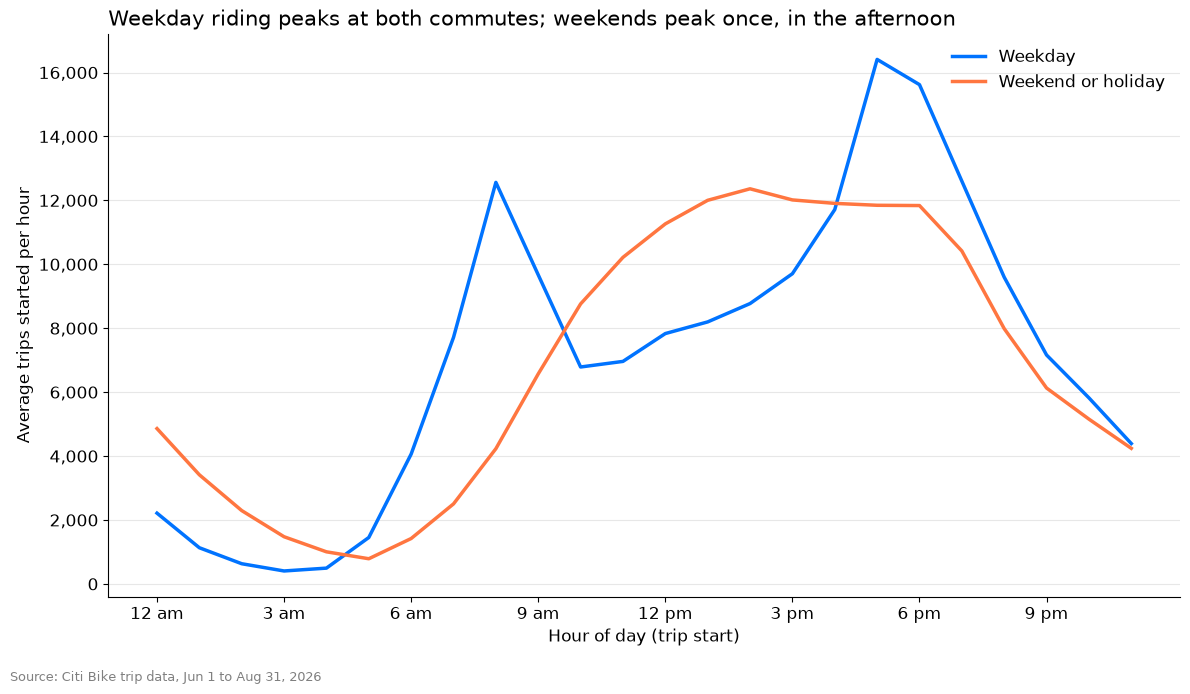

In [6]:
fig, ax = plt.subplots(figsize=(12, 7))
ax.plot(rhythm.index, rhythm["Weekday"], color=BLUE, linewidth=2.5, label="Weekday")
ax.plot(rhythm.index, rhythm["Weekend or holiday"], color=ORANGE, linewidth=2.5, label="Weekend or holiday")
ax.set_xticks(range(0, 24, 3), ["12 am", "3 am", "6 am", "9 am", "12 pm", "3 pm", "6 pm", "9 pm"])
ax.yaxis.set_major_formatter("{x:,.0f}")
ax.grid(axis="y", alpha=0.3)
ax.set(xlabel="Hour of day (trip start)", ylabel="Average trips started per hour")
ax.set_title("Weekday riding peaks at both commutes; weekends peak once, in the afternoon", loc="left", fontsize=15)
ax.legend(frameon=False)
save_chart(fig, "commute_rhythm.png", TRIPS_SOURCE)

### 2. Rain

**Does rain keep people off bikes?** Yes. Heavy-rain days (0.25 in or more) averaged 24% fewer trips than dry days (about 142,600 against 186,800), and light-rain days 9% fewer. Weekdays alone show the same drop (24.5% on heavy-rain days), so it is not just weekends landing on rainy days. Rain is a daily total, so a storm at 3 am counts the same as one at rush hour.

In [7]:
days = daily.merge(weather, on="date")
days["rain"] = pd.cut(days["precip_in"], bins=[0, 0.01, 0.25, np.inf], right=False, labels=["Dry", "Light", "Heavy"])

all_days = days.groupby("rain", observed=True)["trips"].agg(days="count", avg_trips="mean")
weekdays_only = days[days["is_weekday"]].groupby("rain", observed=True)["trips"].agg(days="count", avg_trips="mean")
for table in [all_days, weekdays_only]:
    table["% vs dry"] = (table["avg_trips"] / table.loc["Dry", "avg_trips"] - 1) * 100
pd.concat({"All days": all_days, "Weekdays only": weekdays_only}, axis=1).round(1)

All days                    Weekdays only                   
          days avg_trips % vs dry          days avg_trips % vs dry
rain                                                              
Dry         33  186841.5      0.0            23  189118.8      0.0
Light       38  169844.1     -9.1            27  172378.7     -8.9
Heavy       21  142578.6    -23.7            14  142734.5    -24.5

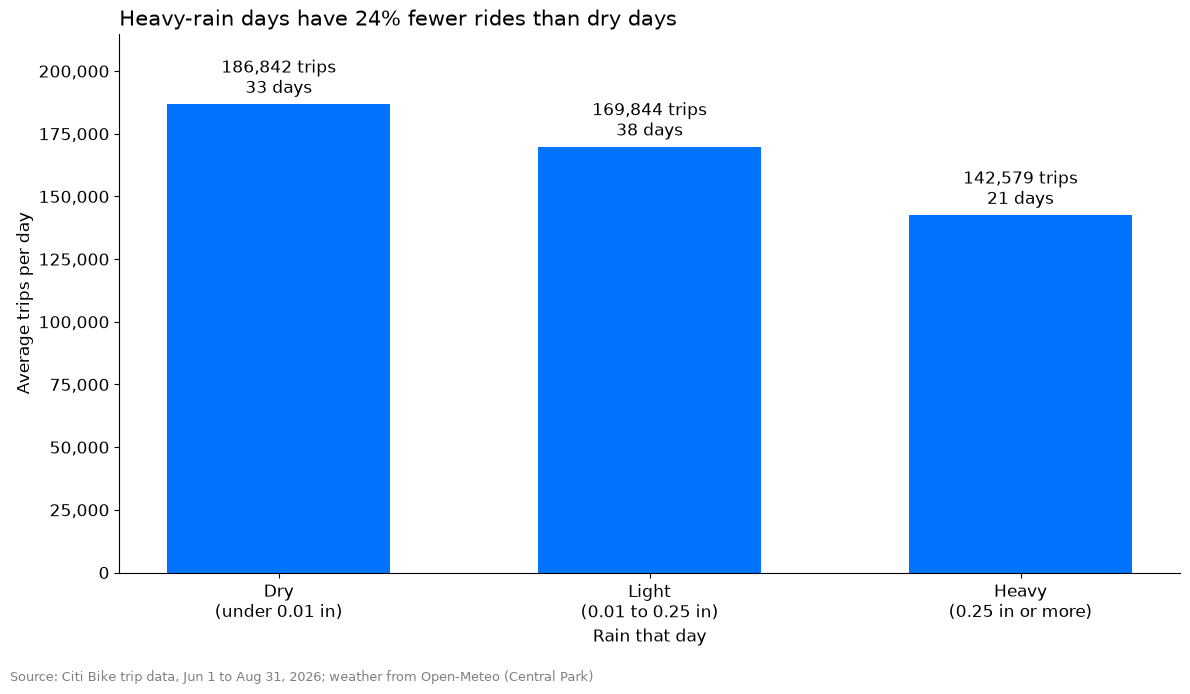

In [8]:
fig, ax = plt.subplots(figsize=(12, 7))
bars = ax.bar(["Dry\n(under 0.01 in)", "Light\n(0.01 to 0.25 in)", "Heavy\n(0.25 in or more)"],
              all_days["avg_trips"], color=BLUE, width=0.6)
ax.bar_label(bars, labels=[f"{m:,.0f} trips\n{n} days" for m, n in zip(all_days["avg_trips"], all_days["days"])], padding=4)
ax.set_ylim(0, all_days["avg_trips"].max() * 1.15)  # headroom for the bar labels
ax.yaxis.set_major_formatter("{x:,.0f}")
ax.set(xlabel="Rain that day", ylabel="Average trips per day")
ax.set_title(f"Heavy-rain days have {-all_days.loc['Heavy', '% vs dry']:.0f}% fewer rides than dry days", loc="left", fontsize=15)
save_chart(fig, "rain_effect.png", TRIPS_SOURCE + "; weather from Open-Meteo (Central Park)")

### 3. Morning drainers and station types

**Which stations empty out on weekday mornings, and how common is that?** W 43 St & 10 Ave loses about 65 bikes between 7 and 10 am on an average non-holiday weekday. All ten of the biggest drainers are in Manhattan near its east or west edge (Avenues A and B, 10th and 11th Avenues, Riverside Blvd, FDR Drive). Of the 2,350 stations averaging at least 1 trip a day, 845 (36%) fill in the morning, meaning they gain bikes on average between 7 and 10 am, and 1,505 (64%) empty. Many stations are close to balanced: a third gain or lose less than 1 bike on an average weekday morning.

In [9]:
stations = load("stations", holidays=holidays_df["date"])
stations["trips_per_day"] = stations["trips"] / len(daily)  # divide by days, not rows
stations["morning_net"] = stations["morning_net_total"] / daily["is_weekday"].sum()  # bikes gained per weekday, 7-10 am
drainers = stations.nsmallest(10, "morning_net")
drainers[["station_id", "name", "morning_net"]]

,station_id,name,morning_net
34,6756.01,W 43 St & 10 Ave,-64.750000
69,5659.05,E 10 St & Ave A,-58.312500
89,7183.03,Riverside Blvd & W 67 St,-58.250000
334,5584.04,E 6 St & Ave B,-54.875000
121,6756.05,W 44 St & 11 Ave,-52.750000
172,7023.04,W 59 St & 10 Ave,-50.671875
104,6230.04,FDR Drive & E 35 St,-50.296875
106,5515.02,E 2 St & Ave B,-48.828125
408,5335.07,Grand St & Samuel Dickstein Plaza,-47.671875
277,5779.09,E 13 St & Ave A,-46.281250


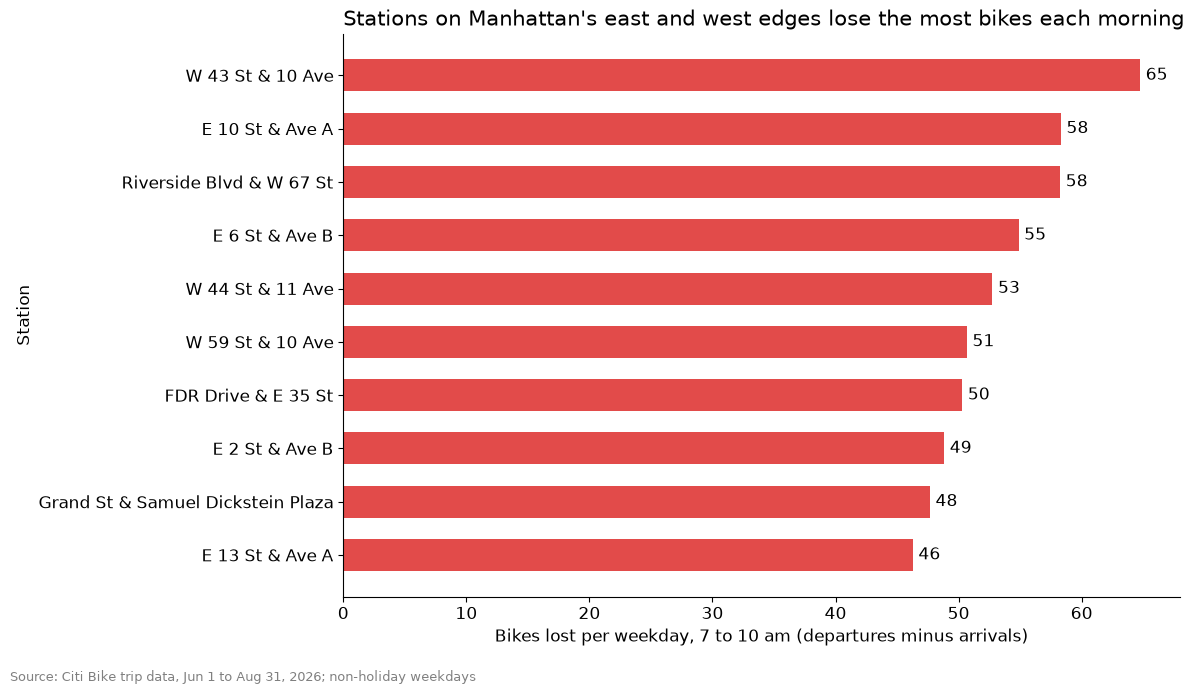

In [10]:
fig, ax = plt.subplots(figsize=(12, 7))
top = drainers.iloc[::-1]  # biggest bar at the top
bars = ax.barh(top["name"], -top["morning_net"], color=RED, height=0.6)
ax.bar_label(bars, fmt="%.0f", padding=4)
ax.set(xlabel="Bikes lost per weekday, 7 to 10 am (departures minus arrivals)", ylabel="Station")
ax.set_title("Stations on Manhattan's east and west edges lose the most bikes each morning", loc="left", fontsize=15)
save_chart(fig, "morning_drainers.png", TRIPS_SOURCE + "; non-holiday weekdays")

In [11]:
stations["station_type"] = np.where(stations["morning_net"] > 0, "Fills in the morning", "Empties in the morning")
busy = stations[stations["trips_per_day"] >= 1]
print(f"Close to balanced (under 1 bike gained or lost per weekday morning): {(busy['morning_net'].abs() < 1).mean():.0%}")
type_counts = busy["station_type"].value_counts()
pd.DataFrame({"stations": type_counts, "share": type_counts / len(busy)}).round(2)

Close to balanced (under 1 bike gained or lost per weekday morning): 33%


,stations,share
station_type,,
Empties in the morning,1505,0.64
Fills in the morning,845,0.36


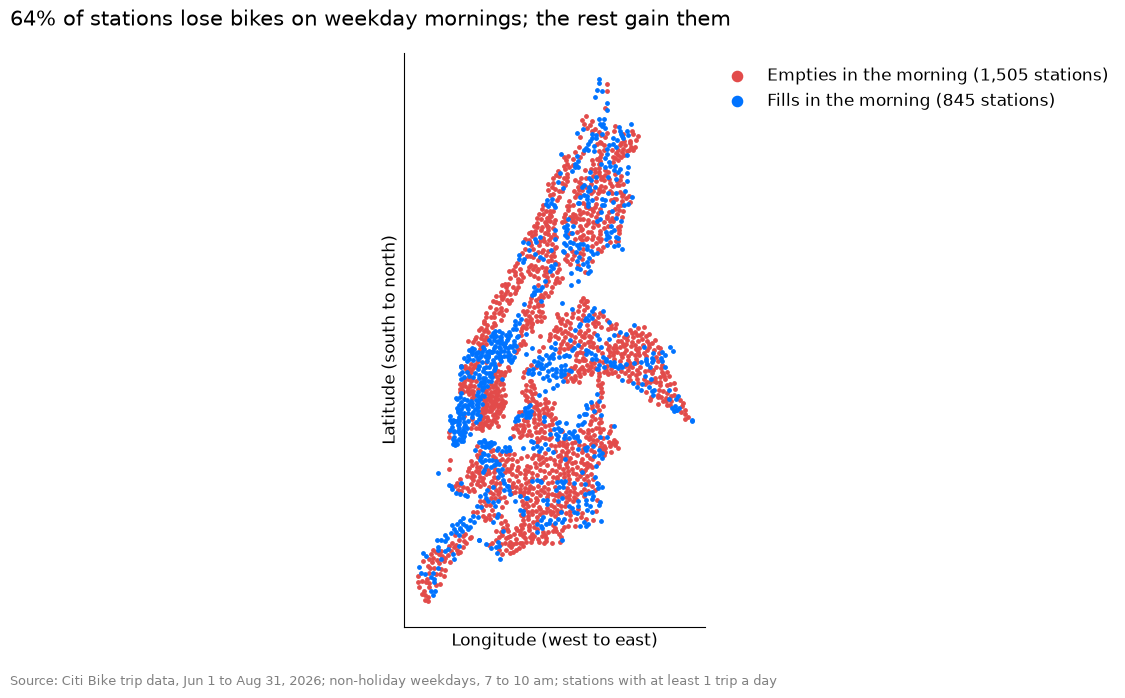

In [12]:
TYPE_COLORS = {"Empties in the morning": RED, "Fills in the morning": BLUE}
fig, ax = plt.subplots(figsize=(12, 7))
for name, group in busy.groupby("station_type"):
    x = group["lng"] * np.cos(np.radians(40.73))  # shrink longitude so the map isn't stretched east-west
    ax.scatter(x, group["lat"], s=6, color=TYPE_COLORS[name], label=f"{name} ({len(group):,} stations)")
ax.set_aspect("equal")
ax.set(xticks=[], yticks=[], xlabel="Longitude (west to east)", ylabel="Latitude (south to north)")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1, 1), markerscale=3)
empties_share = type_counts["Empties in the morning"] / len(busy)
fig.suptitle(f"{empties_share:.0%} of stations lose bikes on weekday mornings; the rest gain them", x=0.01, ha="left", fontsize=15)
save_chart(fig, "station_types.png", TRIPS_SOURCE + "; non-holiday weekdays, 7 to 10 am; stations with at least 1 trip a day")

## Next-day forecast

**How many rides will start at each station tomorrow?** Gradient boosting, using each station's recent rides, the calendar and the weather, misses by 13.49 rides per station-day over the last 14 days. That is 7.2% better than the baseline of repeating the same day last week (14.53), and 13.9% better on RMSE, so it avoids more of the big misses. The gain is largest at small and mid-sized stations (13 to 19% lower MAE below 100 rides a day); at the busiest stations (200+ rides a day) the model only ties the baseline (0.4% lower MAE). Recent rides matter most, and rain is the only other feature with a clear effect.

The importance table explains the fitted model; it was not used to build it. **Caveat:** the test uses each day's actual weather, not a weather forecast, so the results are slightly optimistic.

In [13]:
rides = (load("daily_station_rides")
         .set_index("date").groupby("station_id")["rides"]
         .resample("D").sum().reset_index())  # zero-fills missing days within each station's range, so shift(7) is 7 days ago
by_station = rides.groupby("station_id")["rides"]
rides["rides_yesterday"] = by_station.shift(1)
rides["rides_last_week"] = by_station.shift(7)
rides["avg_last_7"] = by_station.transform(lambda s: s.shift(1).rolling(7).mean())  # shift first, so it excludes the day itself
rides["day_of_week"] = rides["date"].dt.dayofweek  # 0 = Monday
rides["is_holiday"] = rides["date"].isin(holidays_df["date"]).astype(int)
data = rides.merge(weather, on="date").dropna()  # drops each station's first week, which has no full history
data.head()

,station_id,date,rides,rides_yesterday,rides_last_week,avg_last_7,day_of_week,is_holiday,temp_max_f,precip_in
7,1234.56,2026-06-08,17,17.0,16.0,12.571429,0,0,76.1,0.000
8,1234.56,2026-06-09,13,17.0,8.0,12.714286,1,0,81.9,0.000
9,1234.56,2026-06-10,10,13.0,13.0,13.428571,2,0,84.0,0.110
10,1234.56,2026-06-11,17,10.0,7.0,13.000000,3,0,94.2,0.138
11,1234.56,2026-06-12,7,17.0,13.0,14.428571,4,0,93.9,0.201


In [14]:
FEATURES = ["rides_yesterday", "rides_last_week", "avg_last_7", "day_of_week", "is_holiday", "temp_max_f", "precip_in"]
test_start = data["date"].max() - pd.Timedelta(days=13)  # the last 14 days are the test set
train, test = data[data["date"] < test_start], data[data["date"] >= test_start]
print(f"Train: {train['date'].min():%b %-d} to {train['date'].max():%b %-d} ({len(train):,} rows)")
print(f"Test:  {test['date'].min():%b %-d} to {test['date'].max():%b %-d} ({len(test):,} rows)")

Train: Jun 8 to Aug 17 (160,940 rows)
Test:  Aug 18 to Aug 31 (32,141 rows)


In [15]:
model = HistGradientBoostingRegressor(max_iter=300, early_stopping=False, random_state=42)
model.fit(train[FEATURES], train["rides"])
test = test.assign(prediction=model.predict(test[FEATURES]))  # the only time the test set is used

results = pd.DataFrame({
    "baseline": [mean_absolute_error(test["rides"], test["rides_last_week"]), root_mean_squared_error(test["rides"], test["rides_last_week"])],
    "model": [mean_absolute_error(test["rides"], test["prediction"]), root_mean_squared_error(test["rides"], test["prediction"])],
}, index=["MAE", "RMSE"])
results["improvement (%)"] = (1 - results["model"] / results["baseline"]) * 100
results.round(2)

,baseline,model,improvement (%)
MAE,14.53,13.49,7.20
RMSE,30.72,26.45,13.89


In [16]:
errors = pd.DataFrame({
    "baseline MAE": (test["rides"] - test["rides_last_week"]).abs(),
    "model MAE": (test["rides"] - test["prediction"]).abs(),
})
size = pd.cut(test["avg_last_7"], [0, 20, 100, 200, np.inf], right=False, labels=["under 20", "20-100", "100-200", "200+"])
by_size = errors.groupby(size, observed=True).mean()  # station size = average daily rides over the previous 7 days
by_size["improvement (%)"] = (1 - by_size["model MAE"] / by_size["baseline MAE"]) * 100
by_size.round(1)

,baseline MAE,model MAE,improvement (%)
avg_last_7,,,
under 20,4.1,3.3,18.6
20-100,10.8,9.4,13.1
100-200,27.4,26.0,5.0
200+,45.9,45.8,0.4


In [17]:
importance = permutation_importance(model, test[FEATURES], test["rides"], scoring="neg_mean_absolute_error",
                                    n_repeats=5, random_state=42)
pd.Series(importance.importances_mean, index=FEATURES, name="rise in test MAE when shuffled").sort_values(ascending=False).round(2)

avg_last_7         28.38
rides_yesterday    21.77
rides_last_week    12.46
precip_in           3.13
is_holiday          0.00
day_of_week        -0.19
temp_max_f         -0.32
Name: rise in test MAE when shuffled, dtype: float64